In [1]:
import sys, torch
print(sys.executable)
print(torch.cuda.is_available())
D = "results"

C:\dev\dermamnist-transfer-study\.venv\Scripts\python.exe
True


In [2]:
import os
import numpy as np
from derma.metrics import softmax
from derma.calibration import TemperatureScaler, expected_calibration_error, plot_reliability
import matplotlib.pyplot as plt

D = os.path.join("..", "results")

strategies = {
    "Cross-entropy":   "expB_ce_seed0",
    "Weighted CE":     "expB_weighted_ce_seed0",
    "Oversampling":    "expB_oversample_seed0",
    "Focal Loss":      "expB_focal_seed0",
}

print(f"{'Strategy':<18} {'T':>6} {'ECE before':>12} {'ECE after':>12}")
print("-" * 52)

results_table = []

for name, run in strategies.items():
    path = os.path.join(D, "runs", run, "val_logits.npz")
    if not os.path.isfile(path):
        print(f"{name:<18}  FILE NOT FOUND: {path}")
        continue
    
    z = np.load(path)
    logits, labels = z["logits"], z["labels"]
    
    scaler = TemperatureScaler()
    T = scaler.fit(logits, labels)
    
    ece_before = expected_calibration_error(softmax(logits), labels, n_bins=15)
    ece_after = expected_calibration_error(softmax(scaler.transform(logits)), labels, n_bins=15)
    
    print(f"{name:<18} {T:>6.2f} {ece_before:>12.3f} {ece_after:>12.3f}")
    results_table.append((name, T, ece_before, ece_after))

Strategy                T   ECE before    ECE after
----------------------------------------------------
Cross-entropy        2.49        0.127        0.027
Weighted CE          2.16        0.128        0.021
Oversampling         1.54        0.085        0.028
Focal Loss           1.23        0.039        0.032


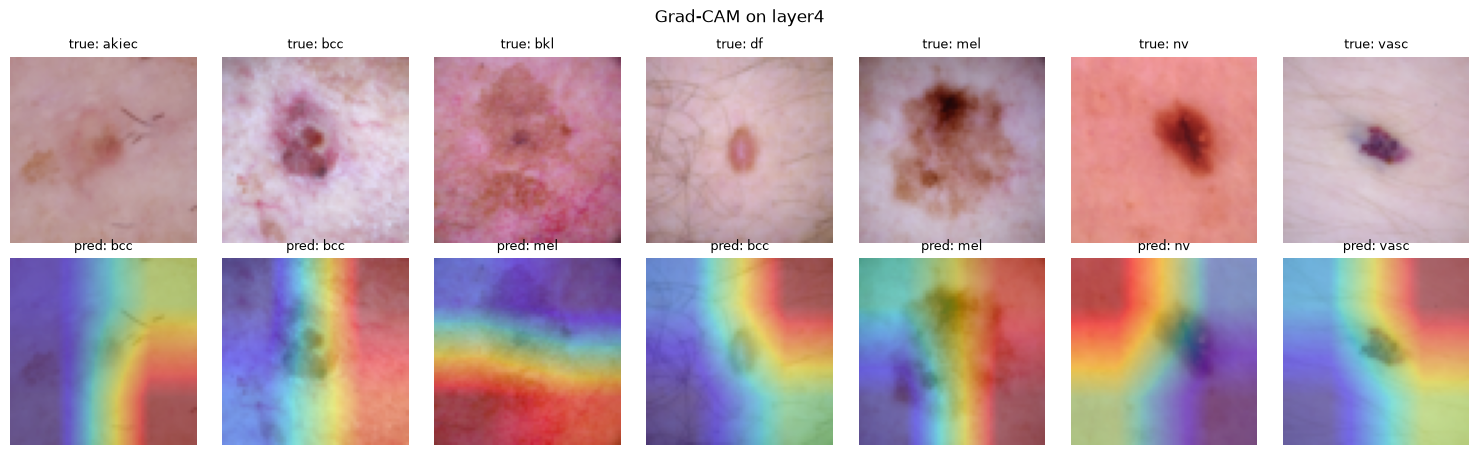

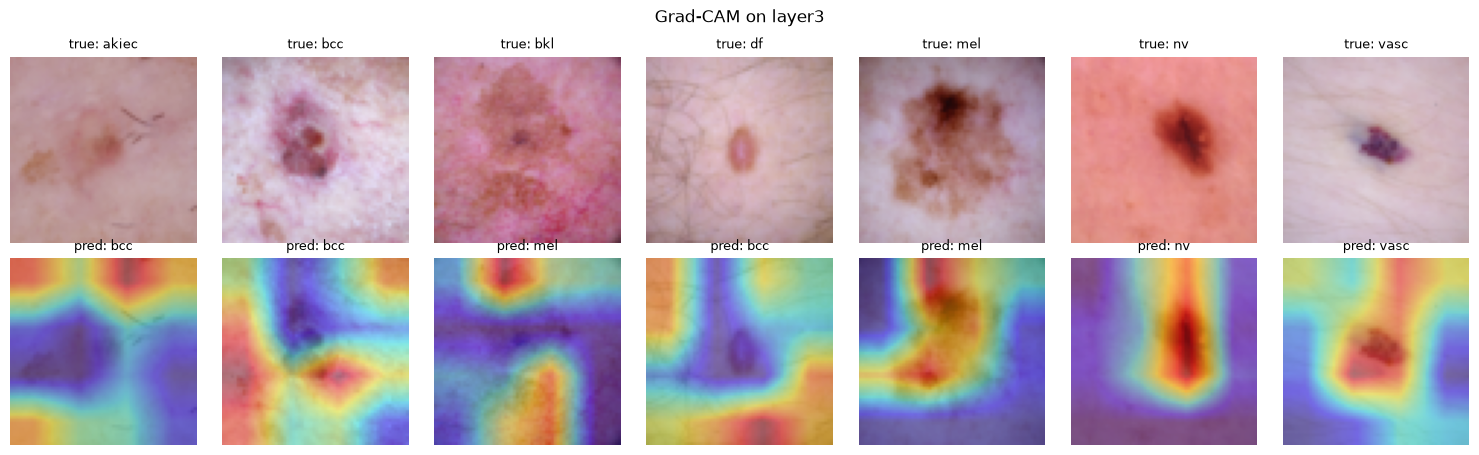

In [3]:
import matplotlib.pyplot as plt
from derma.data import DermaDataset, build_transforms, CLASS_NAMES
from derma.models import build_model
from derma.gradcam import GradCAM

ds = DermaDataset("val", 64, "../data", build_transforms(False))
model = build_model("resnet18_pretrained", load_weights=False)
model.load_state_dict(torch.load(os.path.join(D, "runs", "expB_ce_seed0", "best.pt"), map_location="cpu")["model"])

idx = [ds.labels.tolist().index(c) for c in range(7)]       # First picture of each class
x = torch.stack([ds[i][0] for i in idx])
for layer_name in ["layer4", "layer3"]:
    cams, logits, pred = GradCAM(model, getattr(model, layer_name))(x)
    fig, axes = plt.subplots(2, 7, figsize=(15, 4.6))
    for j, i in enumerate(idx):
        axes[0, j].imshow(ds.images[i]); axes[0, j].set_title(f"true: {CLASS_NAMES[ds.labels[i]]}", fontsize=9)
        axes[1, j].imshow(ds.images[i]); axes[1, j].imshow(cams[j], cmap="jet", alpha=0.45)
        axes[1, j].set_title(f"pred: {CLASS_NAMES[pred[j]]}", fontsize=9)
    for ax in axes.flat: ax.axis("off")
    fig.suptitle(f"Grad-CAM on {layer_name}"); plt.tight_layout(); plt.show()

T = 2.495


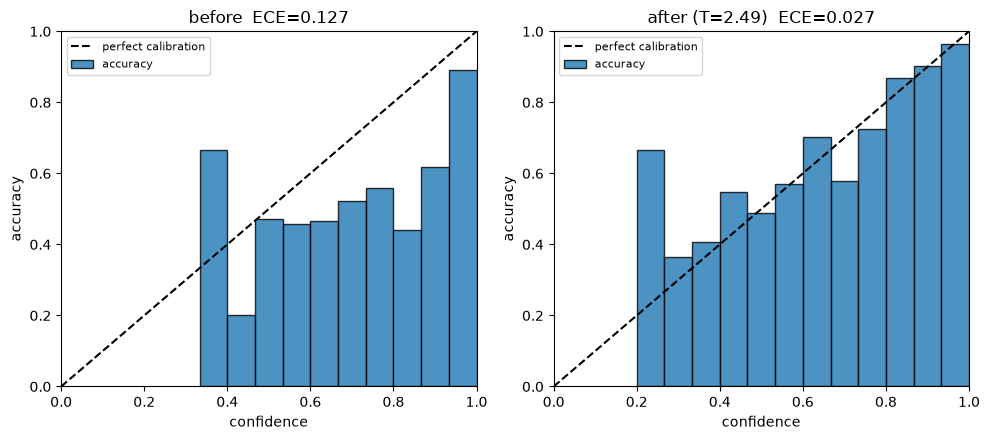

In [4]:
import numpy as np
from derma.metrics import softmax
from derma.calibration import TemperatureScaler, expected_calibration_error, plot_reliability

z = np.load(f"{D}/runs/expB_ce_seed0/val_logits.npz")
logits, labels = z["logits"], z["labels"]
scaler = TemperatureScaler(); T = scaler.fit(logits, labels)
print(f"T = {T:.3f}")
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
plot_reliability(axes[0], softmax(logits), labels, title="before")
plot_reliability(axes[1], softmax(scaler.transform(logits)), labels, title=f"after (T={T:.2f})")
plt.tight_layout(); plt.show()

T = 2.161


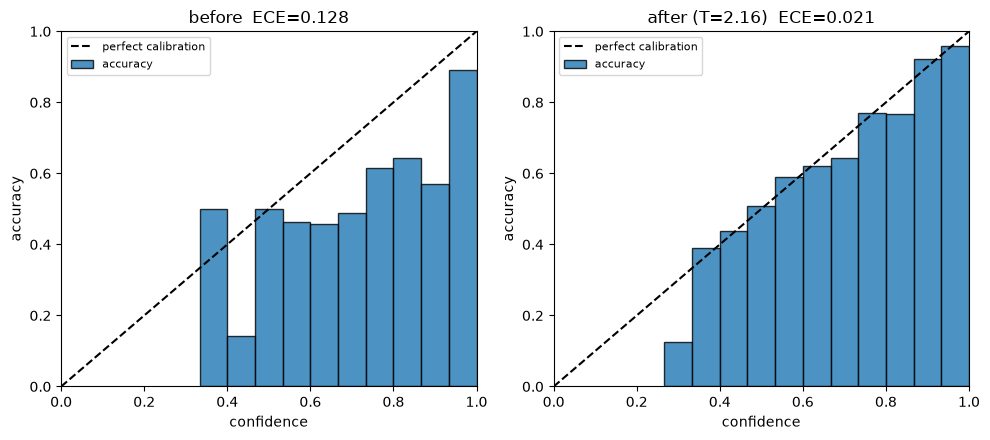

In [5]:
import numpy as np
from derma.metrics import softmax
from derma.calibration import TemperatureScaler, expected_calibration_error, plot_reliability

z = np.load(f"{D}/runs/expB_weighted_ce_seed0/val_logits.npz")
logits, labels = z["logits"], z["labels"]
scaler = TemperatureScaler(); T = scaler.fit(logits, labels)
print(f"T = {T:.3f}")
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
plot_reliability(axes[0], softmax(logits), labels, title="before")
plot_reliability(axes[1], softmax(scaler.transform(logits)), labels, title=f"after (T={T:.2f})")
plt.tight_layout(); plt.show()

T = 1.229


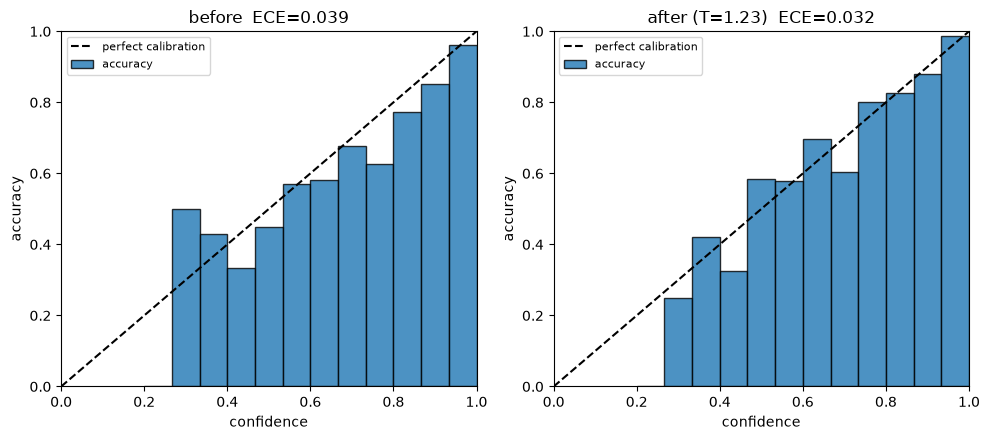

In [6]:
import numpy as np
from derma.metrics import softmax
from derma.calibration import TemperatureScaler, expected_calibration_error, plot_reliability

z = np.load(f"{D}/runs/expB_focal_seed0/val_logits.npz")
logits, labels = z["logits"], z["labels"]
scaler = TemperatureScaler(); T = scaler.fit(logits, labels)
print(f"T = {T:.3f}")
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
plot_reliability(axes[0], softmax(logits), labels, title="before")
plot_reliability(axes[1], softmax(scaler.transform(logits)), labels, title=f"after (T={T:.2f})")
plt.tight_layout(); plt.show()

T = 1.538


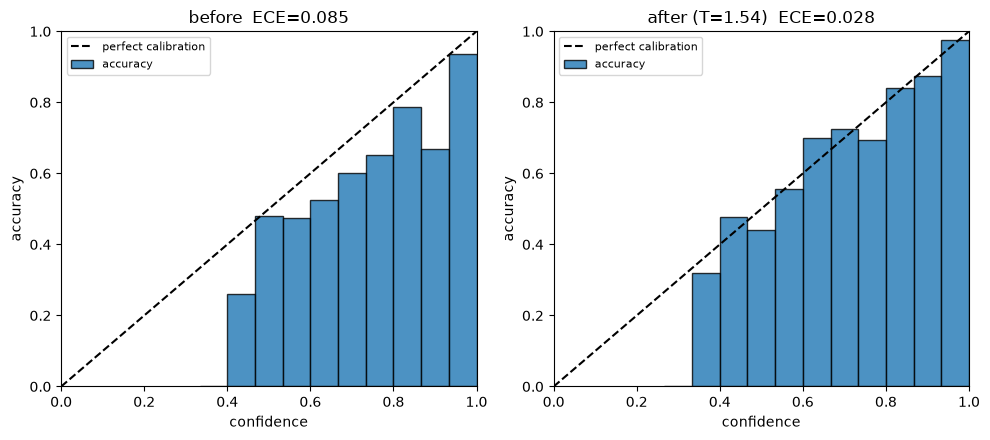

In [7]:
import numpy as np
from derma.metrics import softmax
from derma.calibration import TemperatureScaler, expected_calibration_error, plot_reliability

z = np.load(f"{D}/runs/expB_oversample_seed0/val_logits.npz")
logits, labels = z["logits"], z["labels"]
scaler = TemperatureScaler(); T = scaler.fit(logits, labels)
print(f"T = {T:.3f}")
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
plot_reliability(axes[0], softmax(logits), labels, title="before")
plot_reliability(axes[1], softmax(scaler.transform(logits)), labels, title=f"after (T={T:.2f})")
plt.tight_layout(); plt.show()

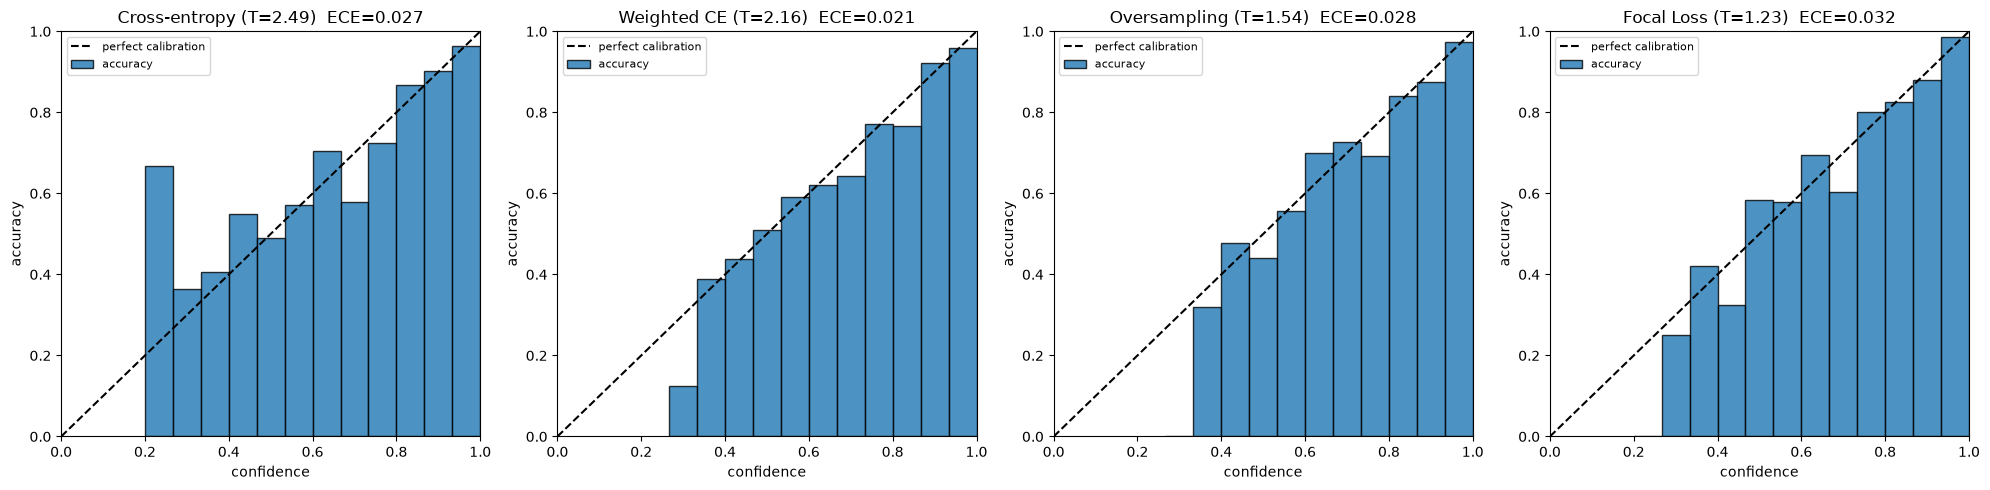

Saved to figures/calibration_all_strategies.png


In [8]:
import os
import numpy as np
from derma.metrics import softmax
from derma.calibration import TemperatureScaler, expected_calibration_error, plot_reliability
import matplotlib.pyplot as plt

D = os.path.join("..", "results")

strategies = {
    "Cross-entropy":   "expB_ce_seed0",
    "Weighted CE":     "expB_weighted_ce_seed0",
    "Oversampling":    "expB_oversample_seed0",
    "Focal Loss":      "expB_focal_seed0",
}

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for ax, (name, run) in zip(axes, strategies.items()):
    path = os.path.join(D, "runs", run, "val_logits.npz")
    z = np.load(path)
    logits, labels = z["logits"], z["labels"]
    
    scaler = TemperatureScaler()
    T = scaler.fit(logits, labels)
    
    plot_reliability(ax, softmax(scaler.transform(logits)), labels, title=f"{name} (T={T:.2f})")

plt.tight_layout()
plt.savefig("../figures/calibration_all_strategies.png", dpi=100, bbox_inches="tight")
plt.show()
print("Saved to figures/calibration_all_strategies.png")